## Nested CNFs with Likelihood Ratio Hypothesis Testing (Wilk)

In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint   # no adjoint... for now
import matplotlib.pyplot as plt
import scipy.stats as stats

from data_utils_2d import make_two_moons_loaders, standard_normal_logprob

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### CNF setup

In [3]:
class ConcatSquash(nn.Module):
    """
    ConcatSquash layer from FFJORD (Grathwohl et al. 2019).
    Computes: lin1(x) * sigmoid(lin2(t)) + lin3(t)
    Time acts multiplicatively on the hidden state at every layer,
    rather than just being an extra input feature.
    """
    def __init__(self, in_dim: int, out_dim: int):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, out_dim)
        self.lin2 = nn.Linear(1, out_dim)
        self.lin3 = nn.Linear(1, out_dim, bias=False)

    def forward(self, t: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        # t is a scalar; expand to (batch, 1) for linear layers
        t_col = t.reshape(1, 1).expand(x.shape[0], 1)
        return self.lin1(x) * torch.sigmoid(self.lin2(t_col)) + self.lin3(t_col)


class ODEFunc(nn.Module):
    """
    Neural vector field f_theta(t, x).
    Used directly for sampling (forward pass, no trace needed).
    """
    def __init__(self, dim: int = 2, hidden_dim: int = 32):
        super().__init__()
        self.dim = dim
        self.cs1 = ConcatSquash(dim, hidden_dim)
        self.cs2 = ConcatSquash(hidden_dim, hidden_dim)
        self.cs3 = ConcatSquash(hidden_dim, dim)

    def forward(self, t: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        x = torch.tanh(self.cs1(t, x))
        x = torch.tanh(self.cs2(t, x))
        return self.cs3(t, x)


class AugmentedODE(nn.Module):
    """
    Augmented ODE for training and encoding:
        d/dt [x, log p] = [f(t,x),  -tr(df/dx)]

    The trace is computed exactly (d=2 costs 2 backward passes).
    We compute dxdt twice:
      - on a detached copy of x  --> gives the trace without breaking the graph
      - on the original x        --> preserves the weight gradient path for loss.backward()
    This two-pass trick is necessary because torchdiffeq flattens the state
    tuple into a single buffer, making x a non-leaf view on which
    requires_grad_(True) is a no-op.
    """
    def __init__(self, odefunc: ODEFunc):
        super().__init__()
        self.odefunc = odefunc

    def forward(self, t, states):
        x, logp = states

        # Pass 1: detached leaf for the exact trace
        x_leaf = x.detach().requires_grad_(True)
        dxdt_leaf = self.odefunc(t, x_leaf)
        trace = torch.zeros(x.shape[0], device=x.device)
        for i in range(x.shape[1]):
            g = torch.autograd.grad(
                dxdt_leaf[:, i].sum(), x_leaf,
                retain_graph=(i < x.shape[1] - 1),
            )[0]
            trace = trace + g[:, i]

        # Pass 2: original x to keep weight gradients alive
        dxdt = self.odefunc(t, x)

        return dxdt, -trace


class CNFModel(nn.Module):
    """
    Continuous normalising flow.

    - log_prob / encode: integrate AugmentedODE backward (t1 -> t0)
    - sample: integrate plain ODEFunc forward (t0 -> t1)
      Kidger's key insight: sampling never needs the trace, so using the
      augmented system for generation is both wasteful and destabilising.
    """
    def __init__(self, dim: int = 2, hidden_dim: int = 32,
                 t0: float = 0.0, t1: float = 1.0):
        super().__init__()
        self.t0, self.t1 = t0, t1
        self.dim = dim
        self.odefunc  = ODEFunc(dim=dim, hidden_dim=hidden_dim)
        self.augmented = AugmentedODE(self.odefunc)

    def _solve(self, func, y0, t_start, t_end):
        ts = torch.tensor([t_start, t_end], device=y0[0].device
                          if isinstance(y0, tuple) else y0.device)
        return odeint(func, y0, ts, method="dopri5", rtol=1e-4, atol=1e-4)

    def log_prob(self, x: torch.Tensor) -> torch.Tensor:
        logp0 = torch.zeros(x.shape[0], device=x.device)
        with torch.enable_grad():
            result = self._solve(self.augmented, (x, logp0), self.t1, self.t0)
        z, delta_logp = result[0][-1], result[1][-1]
        return standard_normal_logprob(z) + delta_logp

    @torch.no_grad()
    def sample(self, n: int) -> torch.Tensor:
        """
        Generate samples by integrating only the plain vector field forward.
        No trace computation -- clean, fast, and numerically stable.
        Tighter tolerances than training to keep the forward trajectory stable.
        """
        z = torch.randn(n, self.dim, device=device)
        ts = torch.tensor([self.t0, self.t1], device=device)
        traj = odeint(self.odefunc, z, ts, method="dopri5", rtol=1e-5, atol=1e-5)
        return traj[-1].detach()

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        """Map data to latent space (for Q-Q diagnostics)."""
        logp0 = torch.zeros(x.shape[0], device=x.device)
        with torch.enable_grad():
            result = self._solve(self.augmented, (x, logp0), self.t1, self.t0)
        return result[0][-1].detach()

    def n_params(self) -> int:
        return sum(p.numel() for p in self.parameters())


# ============================================================
# Training utilities
# ============================================================


def train(model: CNFModel, train_loader, val_loader=None,
          n_epochs: int = 100, lr: float = 5e-4,
          print_every: int = 5, patience: int = 10,
          checkpoint_path: str = "best_model.pt") -> list[float]:
    """Train via MLE with early stopping on validation NLL."""
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    nll_history = []
    best_val_nll = float("inf")
    wait = 0

    for epoch in range(1, n_epochs + 1):
        model.train()
        total, count = 0.0, 0
        for (xb,) in train_loader:
            xb = xb.to(device)
            opt.zero_grad()
            # Noise injection: regularises against memorising exact locations
            xb = xb + 0.01 * torch.randn_like(xb)
            loss = -model.log_prob(xb).mean()
            if not torch.isfinite(loss):
                print(f"  WARNING: non-finite loss, skipping batch")
                opt.zero_grad()
                continue
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            opt.step()
            total += loss.item() * xb.shape[0]
            count += xb.shape[0]

        train_nll = total / count
        nll_history.append(train_nll)

        if val_loader is not None:
            val_nll = mean_nll(model, val_loader)
            if epoch % print_every == 0 or epoch == 1:
                print(f"  epoch {epoch:3d}  train NLL {train_nll:.4f}  val NLL {val_nll:.4f}")
            if val_nll < best_val_nll:
                best_val_nll = val_nll
                wait = 0
                torch.save(model.state_dict(), checkpoint_path)
            else:
                wait += 1
                if wait >= patience:
                    print(f"  Early stopping at epoch {epoch}  (best val NLL {best_val_nll:.4f})")
                    model.load_state_dict(torch.load(checkpoint_path, weights_only=True))
                    break
        else:
            if epoch % print_every == 0 or epoch == 1:
                print(f"  epoch {epoch:3d}  train NLL {train_nll:.4f}")

    return nll_history


@torch.no_grad()
def mean_nll(model: CNFModel, loader) -> float:
    """Mean negative log-likelihood on a DataLoader."""
    model.eval()
    total, count = 0.0, 0
    with torch.enable_grad():
        for (xb,) in loader:
            xb = xb.to(device)
            total += (-model.log_prob(xb)).sum().item()
            count += xb.shape[0]
    return total / count

### Fit nested CNFs and compare NLLs

In [4]:
def fit_nested_cnfs(train_loader, val_loader, test_loader,
                    epochs: int = 100, patience: int = 10):
    """
    Train small (H=16) and large (H=64) CNFs with early stopping.
    Val NLL controls stopping; test NLL is reserved for the LRT.
    """
    print("\n" + "="*60)
    print("Nested CNF comparison")
    print("="*60)

    results = {}
    for name, hdim in [("small (H=16)", 16), ("large (H=64)", 64)]:
        print(f"\nTraining {name} model  (up to {epochs} epochs, patience={patience})...")
        model = CNFModel(dim=2, hidden_dim=hdim).to(device)
        train(model, train_loader, val_loader=val_loader,
              n_epochs=epochs, patience=patience,
              checkpoint_path=f"best_{name.split()[0]}.pt")

        tr_nll = mean_nll(model, train_loader)
        te_nll = mean_nll(model, test_loader)
        print(f"  -> Train NLL: {tr_nll:.4f}   Test NLL: {te_nll:.4f}   Params: {model.n_params()}")

        results[name] = {
            "model":     model,
            "hdim":      hdim,
            "train_nll": tr_nll,
            "test_nll":  te_nll,
            "n_params":  model.n_params(),
        }

    return results


### Likelihood ratio test

In [7]:
def likelihood_ratio_test(results: dict, n_test: int):
    """
    Lambda = 2(ell_1 - ell_0),  ell = -n * mean_NLL.
    Three df choices reported to expose the df sensitivity problem
    that arises when applying the classical LRT to neural networks.
    """
    print("\n" + "="*60)
    print("Likelihood ratio test")
    print("="*60)

    r0 = results["small (H=16)"]
    r1 = results["large (H=64)"]

    ell0   = -r0["test_nll"] * n_test
    ell1   = -r1["test_nll"] * n_test
    Lambda = 2.0 * (ell1 - ell0)

    df_raw    = r1["n_params"] - r0["n_params"]
    df_hidden = (r1["hdim"] - r0["hdim"]) * 2
    df_layers = 2

    p_raw    = 1.0 - stats.chi2.cdf(Lambda, df=df_raw)
    p_hidden = 1.0 - stats.chi2.cdf(Lambda, df=df_hidden)
    p_layers = 1.0 - stats.chi2.cdf(Lambda, df=df_layers)

    print(f"  ell_small = {ell0:.2f}  (mean NLL {r0['test_nll']:.4f})")
    print(f"  ell_large = {ell1:.2f}  (mean NLL {r1['test_nll']:.4f})")
    print(f"  Lambda    = {Lambda:.2f}")
    print(f"  df_raw    = {df_raw}  -> p = {p_raw:.4e}  (naive param count -- degenerate)")
    print(f"  df_hidden = {df_hidden}  -> p = {p_hidden:.4e}  (hidden unit diff x layers)")
    print(f"  df_layers = {df_layers}  -> p = {p_layers:.4e}  (conservative lower bound)")
    print()
    p_val = p_hidden
    if p_val < 0.05:
        print("  -> Reject H0 at 5% level: the larger model fits significantly better.")
    else:
        print("  -> Fail to reject H0: no significant improvement from extra capacity.")

    return Lambda, df_hidden, p_val


### Q-Q plot (in latent space)

In [8]:
def plot_latent_qq(results: dict, x_test: torch.Tensor):
    print("\n" + "="*60)
    print("Q-Q plots of latent coordinates")
    print("="*60)

    for name, r in results.items():
        model = r["model"].eval()
        z = model.encode(x_test.to(device)).cpu().numpy()

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        fig.suptitle(f"Q-Q plots  -  {name}", fontsize=12)

        for ax, (coord, label) in zip(axes, enumerate(["z1", "z2"])):
            stats.probplot(z[:, coord], dist="norm", plot=ax)
            ax.set_title(f"Latent coordinate {label}")
            ax.get_lines()[0].set(markersize=2, alpha=0.5)

        plt.tight_layout()
        fname = f"qq_{name.split()[0]}.png"
        plt.savefig(fname, dpi=150)
        print(f"  Saved {fname}")
        plt.show()


Nested CNF comparison

Training small (H=16) model  (up to 100 epochs, patience=10)...
  epoch   1  train NLL 2.9010  val NLL 2.9563
  epoch   5  train NLL 2.8035  val NLL 2.8661
  epoch  10  train NLL 2.7158  val NLL 2.7674
  epoch  15  train NLL 2.6163  val NLL 2.6719
  epoch  20  train NLL 2.5133  val NLL 2.5671
  epoch  25  train NLL 2.3960  val NLL 2.4429
  epoch  30  train NLL 2.2565  val NLL 2.2912
  epoch  35  train NLL 2.0807  val NLL 2.1073
  epoch  40  train NLL 1.8726  val NLL 1.8922
  epoch  45  train NLL 1.6385  val NLL 1.6524
  epoch  50  train NLL 1.3927  val NLL 1.3981
  epoch  55  train NLL 1.1415  val NLL 1.1405
  epoch  60  train NLL 0.8817  val NLL 0.8877
  epoch  65  train NLL 0.6480  val NLL 0.6440
  epoch  70  train NLL 0.4062  val NLL 0.4107
  epoch  75  train NLL 0.1852  val NLL 0.1892
  epoch  80  train NLL -0.0274  val NLL -0.0210
  epoch  85  train NLL -0.2313  val NLL -0.2200
  epoch  90  train NLL -0.4214  val NLL -0.4085
  epoch  95  train NLL -0.5929  

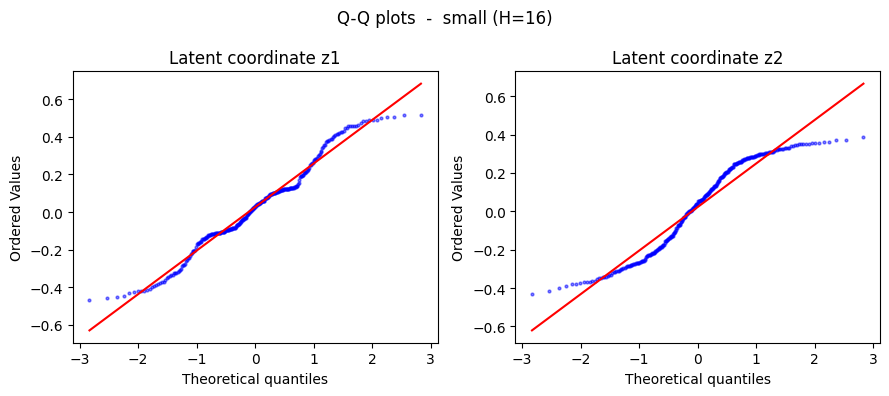

  Saved qq_large.png


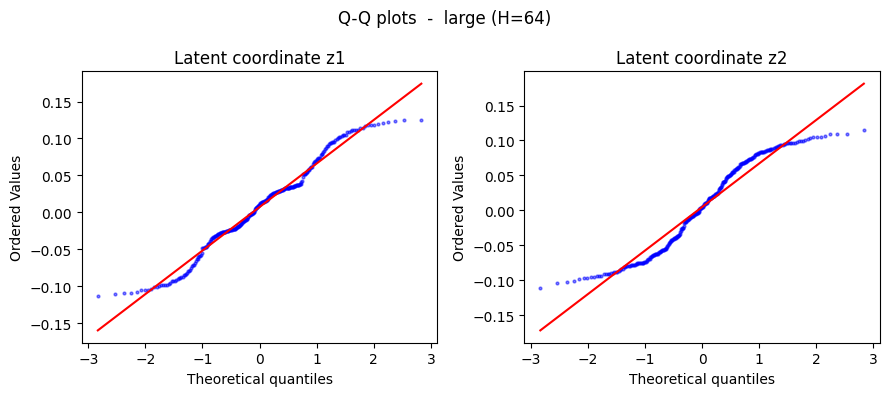

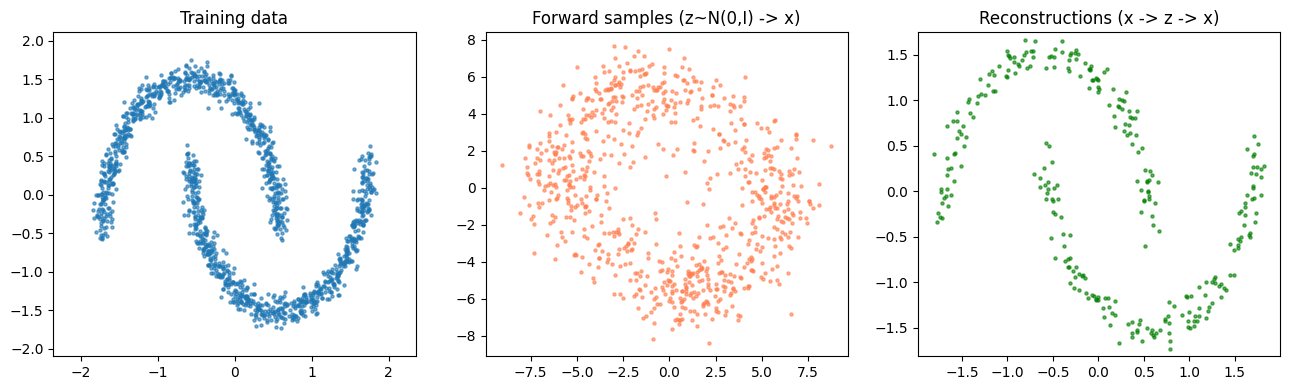

In [11]:
if __name__ == "__main__":
    torch.manual_seed(0)
 
    train_loader, val_loader, test_loader, x_train, x_val, x_test = \
        make_two_moons_loaders(n_samples=2000, batch_size=256)
 
    results = fit_nested_cnfs(train_loader, val_loader, test_loader,
                               epochs=100, patience=10)
 
    likelihood_ratio_test(results, n_test=len(x_test))
 
    plot_latent_qq(results, x_test)
 
    large_model = results["large (H=64)"]["model"].eval()
 
    # --- Forward samples (latent -> data via plain ODEFunc) ---
    samples = large_model.sample(800).cpu()
 
    # --- Reconstructions (data -> latent -> data via encode then forward) ---
    # These use the trained backward map so are guaranteed to look correct.
    # Pure forward samples may diverge if the forward ODE is unstable,
    # which is a known limitation of MLE-only training (the loss only
    # supervises the backward direction).
    with torch.enable_grad():
        z_test = large_model.encode(x_test[:800].to(device))
    ts = torch.tensor([large_model.t0, large_model.t1], device=device)
    with torch.no_grad():
        recon_traj = odeint(large_model.odefunc, z_test, ts,
                            method="dopri5", rtol=1e-5, atol=1e-5)
    recon = recon_traj[-1].cpu()
 
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].scatter(x_train[:, 0], x_train[:, 1], s=5, alpha=0.6)
    axes[0].set_title("Training data")
    axes[0].axis("equal")
 
    axes[1].scatter(samples[:, 0].numpy(), samples[:, 1].numpy(),
                    s=5, alpha=0.6, color="coral")
    axes[1].set_title("Forward samples (z~N(0,I) -> x)")
    axes[1].axis("equal")
 
    axes[2].scatter(recon[:, 0].numpy(), recon[:, 1].numpy(),
                    s=5, alpha=0.6, color="green")
    axes[2].set_title("Reconstructions (x -> z -> x)")
    axes[2].axis("equal")
 
    plt.tight_layout()
    plt.savefig("samples_large.png", dpi=150)
    plt.show()

In [10]:
import inspect
import data_utils_2d
print(inspect.getsource(data_utils_2d.make_two_moons_loaders))

def make_two_moons_loaders(
    n_samples: int = 2000,
    batch_size: int = 256,
    val_split: float = 0.15,
    test_split: float = 0.15,
    noise: float = 0.05,
    seed: int = 42,
):
    """
    Return train/val/test DataLoaders and raw tensors for the two-moons dataset.

    Default split: 70% train, 15% val (early stopping), 15% test (LRT).
    Keeping val and test separate avoids the circularity of stopping on test NLL
    then reporting the same test NLL for the likelihood ratio test.
    """
    X, _ = make_moons(n_samples=n_samples, noise=noise, random_state=seed)

    # Standardise to zero mean, unit variance.
    X = (X - X.mean(0)) / X.std(0)

    n_test = int(n_samples * test_split)
    n_val  = int(n_samples * val_split)

    x_test  = torch.tensor(X[:n_test],              dtype=torch.float32)
    x_val   = torch.tensor(X[n_test:n_test + n_val], dtype=torch.float32)
    x_train = torch.tensor(X[n_test + n_val:],       dtype=torch.float32)

    train_loader = DataLoader